# DATA 620 – Project 1: Centrality in a Network of Criminal Organizations

- **Author:** Kerwin Charles
- **Dataset:** CRIMENET, a knowledge graph of relationships between criminal organizations
  (<https://github.com/alvarofrancomartins/CRIMENET>)

## Introduction

For this project I wanted to stay with the fraud and organized crime theme from this
week's discussion. In the discussion, the idea that kept coming up was that a single
fraudulent account or company can look normal on its own, and it's the connections that
give it away. CRIMENET lets me look at the same idea one level up: instead of accounts or
companies, the nodes are criminal organizations (cartels, mafias, gangs, motorcycle clubs)
and the edges are documented relationships between them.

**My question:** do criminal organizations from different parts of the world hold different
positions in the network of criminal cooperation? I measure position two ways:

- **Degree centrality**, which counts how many partners an organization has.
- **Eigenvector centrality**, which rewards being connected to partners that are themselves
  well connected. An organization can have a modest number of partners and still score high
  if those partners sit at the center of the network.

The categorical variable is each organization's **region of origin**. As a second, simpler
comparison, I also compare **active** and **defunct** organizations.

**Outline**

1. The data and the choices I made
2. Loading the data and building the cooperation network
3. Exploring the network: connectivity, group sizes and ties between regions
4. Degree and eigenvector centrality, and who is most central
5. Comparing the regions, with statistical tests
6. Active vs. defunct organizations
7. Seeing the network, findings and limitations

## The data

CRIMENET was built by Alvaro Franco Martins from Wikipedia articles in English, Italian,
Portuguese and Spanish. An LLM pipeline read 1,418 articles and pulled out every criminal
organization they mention and every relationship between two organizations. Each
relationship keeps the sentence from Wikipedia that supports it, so any edge can be checked
against its source. The data is released under the MIT license.

**Nodes** are organizations. Each organization that has its own Wikipedia article is
"profiled": it has a country of origin, an activity period and a flag for whether it is
defunct. Organizations that only show up as a mention inside someone else's article are
kept in the dataset too, but their country is left empty.

**Edges** come in three types:

| Type | Meaning |
|---|---|
| cooperation | the two organizations work together: alliances, joint operations, supplying or laundering for each other |
| conflict | the two organizations work against each other: wars, killings, rivalries |
| other | structural ties (faction, splinter group, successor) or a vague "linked to" |

**Two choices I made, and why**

1. **Cooperation edges only.** Mixing alliances and wars in one network would make
   centrality hard to interpret. A cartel with 30 enemies would look just as "central" as one
   with 30 allies. Keeping one type of relationship means every edge means the same thing:
   "these two organizations work together."
2. **Profiled organizations only.** The project needs a category for every node, and
   mention-only organizations have no country. Keeping only profiled organizations means
   every node has a region. The trade-off is that ties to mention-only organizations are
   dropped, so some degrees are lower than they would be in the full graph.

The edges are undirected. When several Wikipedia sentences describe the same pair of
organizations working together, I keep one edge and store the number of sentences as
`supporting_statements`.

In [25]:
import json
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats

pd.set_option("display.width", 88)
pd.set_option("display.max_colwidth", 32)

DATA_FOLDER = Path("data")
FIGURE_FOLDER = Path("figures")
DATA_FOLDER.mkdir(exist_ok=True)
FIGURE_FOLDER.mkdir(exist_ok=True)

# Pinned to one commit so the numbers in this notebook don't change if the
# dataset is updated later.
CRIMENET_COMMIT = "5b4a897874a889de2d3c61bd105811a8ebfeda71"
CRIMENET_URLS = [
    ("https://raw.githubusercontent.com/alvarofrancomartins/CRIMENET/"
     f"{CRIMENET_COMMIT}/data/crimenet.json"),
    ("https://github.com/alvarofrancomartins/CRIMENET/raw/"
     f"{CRIMENET_COMMIT}/data/crimenet.json"),
]
CRIMENET_FILE = DATA_FOLDER / "crimenet.json"

import sys
print("Python", sys.version.split()[0], "| networkx", nx.__version__,
      "| pandas", pd.__version__, "| libraries loaded")

Python 3.11.10 | networkx 3.6.1 | pandas 3.0.3 | libraries loaded


## Loading the data

The whole dataset is one JSON file in the CRIMENET GitHub repository. The code downloads it
the first time it runs and reads the saved copy after that.

In [26]:
def download_crimenet(destination, timeout_seconds=20):
    # Try the raw GitHub link first, then GitHub's regular download link.
    # Each attempt gives up after `timeout_seconds` without data instead of
    # waiting forever, and the file is written to a temporary name first so a
    # failed download never leaves a half-written crimenet.json behind.
    temporary_file = destination.with_suffix(".part")
    last_error = None
    for url in CRIMENET_URLS:
        print("Downloading CRIMENET from", url)
        try:
            with urllib.request.urlopen(url, timeout=timeout_seconds) as response, \
                    open(temporary_file, "wb") as output:
                downloaded = 0
                while True:
                    block = response.read(1024 * 1024)
                    if not block:
                        break
                    output.write(block)
                    downloaded += len(block)
            temporary_file.rename(destination)
            print(f"Saved {downloaded / 1e6:.1f} MB to {destination}")
            return
        except Exception as error:
            last_error = error
            temporary_file.unlink(missing_ok=True)
            print(f"  failed: {error}")
    raise RuntimeError(f"Could not download the data: {last_error}")


if not CRIMENET_FILE.exists():
    download_crimenet(CRIMENET_FILE)

with open(CRIMENET_FILE, encoding="utf-8") as file:
    crimenet = json.load(file)

all_organizations = crimenet["nodes"]
all_relationships = crimenet["edges"]

print(f"Organizations in CRIMENET : {len(all_organizations):,}")
print(f"Relationships in CRIMENET : {len(all_relationships):,}")
print("Relationship types        :",
      dict(Counter(edge["relationship"] for edge in all_relationships)))

Organizations in CRIMENET : 4,504
Relationships in CRIMENET : 10,935
Relationship types        : {'other': 2297, 'cooperation': 4907, 'conflict': 3731}


In [27]:
# A quick look at one organization and one relationship
first_organization = all_organizations[0]
print({key: first_organization[key] for key in
       ["standard_name", "country", "time_period", "is_defunct", "profiled"]})
print()
first_cooperation = next(edge for edge in all_relationships
                         if edge["relationship"] == "cooperation")
print(first_cooperation["source"], "<->", first_cooperation["target"])
print("Evidence:", first_cooperation["evidence_quote"][:200])

{'standard_name': "'Ndrangheta", 'country': 'Italy', 'time_period': '19th century-present', 'is_defunct': False, 'profiled': True}

'Ndrangheta <-> American Mafia
Evidence: These Italian crime groups frequently collaborate with the Italian-American Mafia, which is itself an offshoot of the Sicilian Mafia.


### Region of origin

CRIMENET stores a country of origin for each profiled organization. Most countries only have
a handful of organizations, which is too few to compare, so I grouped countries into five
regions. "Latin America" includes Mexico, Central America and the Caribbean. Turkey and the Middle
East are grouped with Africa, and Pakistan and Afghanistan with Asia-Pacific. These are judgement calls, but they only affect a few organizations.

In [28]:
REGION_OF_COUNTRY = {}
COUNTRIES_IN_REGION = {
    "North America": ["United States", "Canada"],
    "Latin America": [
        "Mexico", "Colombia", "Brazil", "Ecuador", "Puerto Rico", "Argentina",
        "Bolivia", "Haiti", "Venezuela", "Curaçao", "Honduras", "Jamaica",
        "Guatemala", "Cuba", "Peru", "El Salvador"],
    "Europe": [
        "Italy", "United Kingdom", "Ireland", "Germany", "Russia", "Denmark",
        "Sweden", "Serbia", "Netherlands", "Spain", "France", "Soviet Union",
        "Poland", "Finland", "Albania"],
    "Asia-Pacific": [
        "Japan", "New Zealand", "Australia", "China", "Hong Kong", "Philippines",
        "Indonesia", "Singapore", "Malaysia", "Taiwan", "India", "Myanmar",
        "Pakistan", "Afghanistan"],
    "Middle East & Africa": [
        "Palestine", "Turkey", "Syria", "Iraq", "Somalia", "Yemen", "Nigeria",
        "Israel", "Saudi Arabia", "Lebanon", "Algeria", "South Africa", "Sudan"],
}
for region, countries in COUNTRIES_IN_REGION.items():
    for country in countries:
        REGION_OF_COUNTRY[country] = region

REGION_ORDER = list(COUNTRIES_IN_REGION)
REGION_COLORS = dict(zip(REGION_ORDER,
                         ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]))


def describe_status(is_defunct):
    # CRIMENET uses True, False or the text "unknown"
    if is_defunct is True:
        return "Defunct"
    if is_defunct is False:
        return "Active"
    return "Unknown"

## Building the cooperation network

In [29]:
profiled_organizations = {org["standard_name"]: org for org in all_organizations
                          if org["profiled"]}

cooperation_network = nx.Graph()
for edge in all_relationships:
    org_a, org_b = edge["source"], edge["target"]
    both_profiled = org_a in profiled_organizations and org_b in profiled_organizations
    if edge["relationship"] != "cooperation" or not both_profiled or org_a == org_b:
        continue
    if cooperation_network.has_edge(org_a, org_b):
        cooperation_network[org_a][org_b]["supporting_statements"] += 1
    else:
        cooperation_network.add_edge(org_a, org_b, supporting_statements=1)

for name in cooperation_network:
    org = profiled_organizations[name]
    cooperation_network.nodes[name]["country"] = org["country"]
    cooperation_network.nodes[name]["region"] = REGION_OF_COUNTRY[org["country"]]
    cooperation_network.nodes[name]["status"] = describe_status(org["is_defunct"])

print(f"Profiled organizations             : {len(profiled_organizations):,}")
print(f"... with at least one cooperation tie: {cooperation_network.number_of_nodes():,}")
print(f"Cooperation ties between them        : {cooperation_network.number_of_edges():,}")
missing_region = [n for n in cooperation_network
                  if cooperation_network.nodes[n]["region"] is None]
print(f"Organizations without a region       : {len(missing_region)}")

Profiled organizations             : 1,032
... with at least one cooperation tie: 722
Cooperation ties between them        : 1,803
Organizations without a region       : 0


## Exploring the network

### Is the network fully connected?

In [30]:
connected_groups = sorted(nx.connected_components(cooperation_network),
                          key=len, reverse=True)
largest_group = cooperation_network.subgraph(connected_groups[0]).copy()
outside_largest_group = [name for group in connected_groups[1:] for name in group]

print(f"Separate groups (components) : {len(connected_groups)}")
print(f"Sizes of the 6 largest       : {[len(group) for group in connected_groups[:6]]}")
print(f"Largest group                : {largest_group.number_of_nodes()} organizations, "
      f"{largest_group.number_of_edges()} ties")
print(f"Organizations outside it     : {len(outside_largest_group)}")
print("Their regions                :",
      dict(Counter(cooperation_network.nodes[n]["region"] for n in outside_largest_group)))

Separate groups (components) : 24
Sizes of the 6 largest       : [659, 12, 5, 4, 4, 2]
Largest group                : 659 organizations, 1752 ties
Organizations outside it     : 63
Their regions                : {'Europe': 21, 'North America': 34, 'Latin America': 2, 'Asia-Pacific': 5, 'Middle East & Africa': 1}


The network is **not** fully connected. Most organizations (659) belong to one large group,
and the rest sit in 23 small groups, the biggest with only 12 members. Eigenvector centrality
only makes sense inside a connected network, so from here on I analyze the **largest group of
659 organizations** for both measures. That way degree and eigenvector centrality are
calculated on exactly the same organizations.

In [31]:
organizations_table = pd.DataFrame.from_dict(dict(largest_group.nodes(data=True)),
                                             orient="index")
organizations_table.index.name = "organization"

region_counts = (organizations_table["region"].value_counts()
                 .reindex(REGION_ORDER).rename("organizations"))
status_counts = organizations_table["status"].value_counts().rename("organizations")
display(region_counts.to_frame())
display(status_counts.to_frame())
print("Top 8 countries:")
display(organizations_table["country"].value_counts().head(8).to_frame())

,organizations
region,
North America,228
Latin America,115
Europe,237
Asia-Pacific,56
Middle East & Africa,23


,organizations
status,
Active,508
Defunct,136
Unknown,15


Top 8 countries:


,count
country,
United States,196
Italy,195
Mexico,50
Canada,32
Colombia,25
Japan,21
Brazil,18
Australia,9


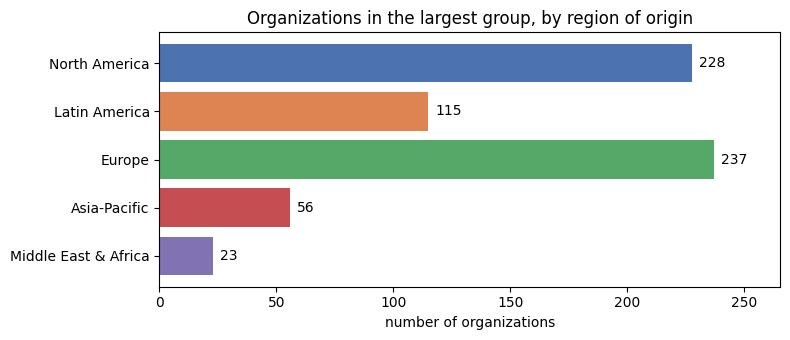

In [32]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(region_counts.index[::-1], region_counts.values[::-1],
        color=[REGION_COLORS[r] for r in region_counts.index[::-1]])
for i, value in enumerate(region_counts.values[::-1]):
    ax.text(value + 3, i, str(value), va="center")
ax.set(title="Organizations in the largest group, by region of origin",
       xlabel="number of organizations", xlim=(0, region_counts.max() * 1.12))
plt.tight_layout()
plt.savefig(FIGURE_FOLDER / "organizations_by_region.png", dpi=150)
plt.show()

The groups are uneven. Europe and North America each have more than 220 organizations, while
the Middle East & Africa has only 23. Europe is mostly Italy: the Italian mafias are split
into many separate family units ('ndrine, clans), and each one is its own node. The United
States is the same story for the American Mafia families and the motorcycle clubs.

### Do organizations cooperate across regions?

Before comparing groups, it's worth checking that ties actually cross between them. If every
region only cooperated with itself, the regions would be separate networks rather than groups
within one network.

In [33]:
region_of = nx.get_node_attributes(largest_group, "region")
ties_between_regions = pd.DataFrame(0, index=REGION_ORDER, columns=REGION_ORDER)
for org_a, org_b in largest_group.edges():
    ties_between_regions.loc[region_of[org_a], region_of[org_b]] += 1
    if region_of[org_a] != region_of[org_b]:
        ties_between_regions.loc[region_of[org_b], region_of[org_a]] += 1

ties_within_region = sum(1 for a, b in largest_group.edges() if region_of[a] == region_of[b])
share_within = ties_within_region / largest_group.number_of_edges()
print(f"Ties within the same region : {ties_within_region} of "
      f"{largest_group.number_of_edges()} ({share_within:.0%})")
print(f"Region assortativity        : "
      f"{nx.attribute_assortativity_coefficient(largest_group, 'region'):.2f}")
short_names = {"North America": "N. Am.", "Latin America": "Lat. Am.", "Europe": "Europe",
               "Asia-Pacific": "Asia-Pac.", "Middle East & Africa": "ME & Afr."}
display(ties_between_regions.rename(columns=short_names))

Ties within the same region : 1501 of 1752 (86%)
Region assortativity        : 0.80


,N. Am.,Lat. Am.,Europe,Asia-Pac.,ME & Afr.
North America,551,61,63,34,3
Latin America,61,302,45,10,8
Europe,63,45,557,4,9
Asia-Pacific,34,10,4,61,14
Middle East & Africa,3,8,9,14,30


In [34]:
# For each region: what share of its organizations' ties go to another region?
outward_share = {}
for region in REGION_ORDER:
    members = [n for n in largest_group if region_of[n] == region]
    all_ties = sum(largest_group.degree(n) for n in members)
    cross_ties = sum(1 for n in members for partner in largest_group[n]
                     if region_of[partner] != region)
    outward_share[region] = cross_ties / all_ties
pd.Series(outward_share, name="share of ties to other regions").round(2).to_frame()

,share of ties to other regions
North America,0.13
Latin America,0.17
Europe,0.10
Asia-Pacific,0.34
Middle East & Africa,0.36


Ties do cross regions, but most cooperation stays close to home: 86% of ties connect two
organizations from the same region, and the assortativity of 0.80 confirms that strong
pull. The regions differ, though. About a third of the ties of Asia-Pacific and Middle
Eastern & African organizations go to another region, compared with 17% for Latin America,
13% for North America and only 10% for Europe.

### How are partners distributed?

count    659.00
mean       5.32
std        6.71
min        1.00
25%        2.00
50%        3.00
75%        6.00
max       64.00


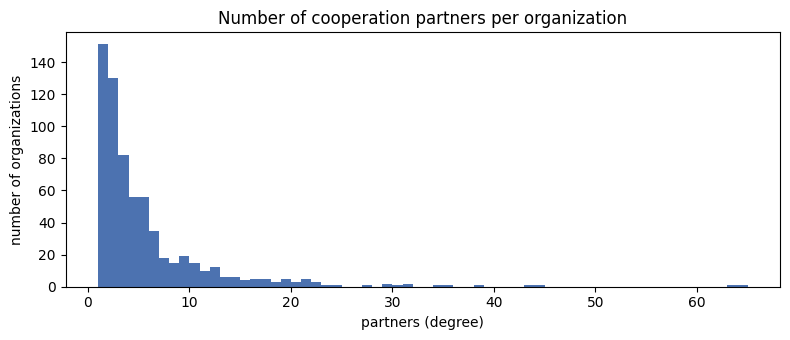

In [35]:
partners = pd.Series(dict(largest_group.degree()), name="partners")
print(partners.describe().round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(partners, bins=range(1, partners.max() + 2), color="#4C72B0")
ax.set(title="Number of cooperation partners per organization",
       xlabel="partners (degree)", ylabel="number of organizations")
plt.tight_layout()
plt.savefig(FIGURE_FOLDER / "partners_distribution.png", dpi=150)
plt.show()

The distribution is very skewed. The median organization has 3 partners, but a few have more
than 40. That skew is the reason I use rank-based tests (Kruskal–Wallis and Mann–Whitney)
alongside the t-test later on: the t-test compares means, and a few huge hubs can pull a mean
around.

## Degree and eigenvector centrality

In [36]:
degree_centrality = nx.degree_centrality(largest_group)
eigenvector_centrality = nx.eigenvector_centrality(largest_group, max_iter=2000)

organizations_table["partners"] = partners
organizations_table["degree_centrality"] = pd.Series(degree_centrality)
organizations_table["eigenvector_centrality"] = pd.Series(eigenvector_centrality)
organizations_table["degree_rank"] = (organizations_table["degree_centrality"]
                                      .rank(ascending=False, method="min").astype(int))
organizations_table["eigenvector_rank"] = (organizations_table["eigenvector_centrality"]
                                           .rank(ascending=False, method="min").astype(int))

organizations_table[["degree_centrality", "eigenvector_centrality"]].describe().round(4)

,degree_centrality,eigenvector_centrality
count,659.0000,659.0000
mean,0.0081,0.0205
std,0.0102,0.0332
min,0.0015,0.0000
25%,0.0030,0.0019
50%,0.0046,0.0093
75%,0.0091,0.0224
max,0.0973,0.2992


Degree centrality is the number of partners divided by the 658 other organizations, so a score
of 0.01 means about 1% of the network. Eigenvector centrality is scaled by networkx so that the
squared scores add up to 1, which means the numbers are only meaningful relative to each other.
Both measures are heavily skewed, with medians far below the maximums.

## Who is most central?

A top 5 is too short to learn much, especially when both measures give the same list. So I
list the **top 20** for each measure side by side and look at where the two lists differ.

In [37]:
OTHER_MEASURE = {"degree_centrality": "eigenvector_centrality",
                 "eigenvector_centrality": "degree_centrality"}


def ranked_by(measure):
    # Organizations often tie on degree (for example, several have exactly 21
    # partners). Breaking ties by the other measure, then by name, keeps the
    # order the same every time the notebook runs.
    return (organizations_table.reset_index()
            .sort_values([measure, OTHER_MEASURE[measure], "organization"],
                         ascending=[False, False, True])
            .set_index("organization"))


def top_organizations(measure, how_many=20):
    top = ranked_by(measure).head(how_many)
    return pd.DataFrame({
        "organization": top.index,
        "region": top["region"].values,
        "partners": top["partners"].values,
        "score": top[measure].round(4).values,
    }, index=range(1, how_many + 1))


top_by_degree = top_organizations("degree_centrality")
top_by_eigenvector = top_organizations("eigenvector_centrality")
print("Top 20 by degree centrality")
display(top_by_degree)
print("Top 20 by eigenvector centrality")
display(top_by_eigenvector)

Top 20 by degree centrality


,organization,region,partners,score
1,Hells Angels Motorcycle Club,North America,64,0.0973
2,Sinaloa Cartel,Latin America,63,0.0957
3,'Ndrangheta,Europe,44,0.0669
4,American Mafia,North America,43,0.0653
5,Cártel de Jalisco Nueva Gene...,Latin America,38,0.0578
6,Gambino crime family,North America,35,0.0532
7,Mexican Mafia,North America,34,0.0517
8,Gulf Cartel,Latin America,31,0.0471
9,Los Zetas,Latin America,31,0.0471
10,Bonanno crime family,North America,30,0.0456


Top 20 by eigenvector centrality


,organization,region,partners,score
1,Sinaloa Cartel,Latin America,63,0.2992
2,Hells Angels Motorcycle Club,North America,64,0.2351
3,Gambino crime family,North America,35,0.2041
4,'Ndrangheta,Europe,44,0.2002
5,American Mafia,North America,43,0.1833
6,Genovese crime family,North America,29,0.1725
7,Cártel de Jalisco Nueva Gene...,Latin America,38,0.1725
8,Gulf Cartel,Latin America,31,0.1702
9,Los Zetas,Latin America,31,0.1605
10,Mexican Mafia,North America,34,0.1519


In [38]:
only_in_degree_top = sorted(set(top_by_degree["organization"]) - set(top_by_eigenvector["organization"]))
only_in_eigenvector_top = sorted(set(top_by_eigenvector["organization"]) - set(top_by_degree["organization"]))
print("Organizations in both top 20 lists:",
      len(set(top_by_degree["organization"]) & set(top_by_eigenvector["organization"])))
print("\nIn the degree top 20 only (many partners, less central partners):")
display(organizations_table.loc[only_in_degree_top,
        ["region", "partners", "degree_rank", "eigenvector_rank"]]
        .sort_values("degree_rank").rename(columns={"degree_rank": "deg rank", "eigenvector_rank": "eig rank"}))
print("In the eigenvector top 20 only (fewer partners, but very central ones):")
display(organizations_table.loc[only_in_eigenvector_top,
        ["region", "partners", "degree_rank", "eigenvector_rank"]]
        .sort_values("eigenvector_rank").rename(columns={"degree_rank": "deg rank", "eigenvector_rank": "eig rank"}))

Organizations in both top 20 lists: 14

In the degree top 20 only (many partners, less central partners):


,region,partners,deg rank,eig rank
organization,,,,
Camorra,Europe,27,13,22
Commisso 'ndrina,Europe,24,14,39
Crips,North America,23,15,54
Latin Kings,North America,22,16,28
Nuova Famiglia,Europe,22,16,112
Outlaws Motorcycle Club,North America,22,16,33


In the eigenvector top 20 only (fewer partners, but very central ones):


,region,partners,deg rank,eig rank
organization,,,,
Detroit Partnership,North America,20,24,13
Tijuana Cartel,Latin America,19,27,14
Los Angeles crime family,North America,17,35,15
La Familia Michoacana,Latin America,17,35,18
Buffalo crime family,North America,17,35,19
Cleveland crime family,North America,14,49,20


In [39]:
# When does each region first show up in the eigenvector ranking?
ranked_by_eigenvector = organizations_table.sort_values("eigenvector_centrality",
                                                        ascending=False)
first_appearance = (ranked_by_eigenvector.reset_index()
                    .groupby("region", sort=False).first())
first_appearance["first_rank"] = [
    int(ranked_by_eigenvector.index.get_loc(name)) + 1
    for name in first_appearance["organization"]]
first_appearance[["organization", "country", "first_rank", "partners"]].sort_values("first_rank")

,organization,country,first_rank,partners
region,,,,
Latin America,Sinaloa Cartel,Mexico,1,63
North America,Hells Angels Motorcycle Club,United States,2,64
Europe,'Ndrangheta,Italy,4,44
Middle East & Africa,Hezbollah,Lebanon,61,11
Asia-Pacific,Yakuza,Japan,66,7


Fourteen of the 20 names are the same in both lists. The Sinaloa Cartel and the Hells Angels are
first and second either way, followed by the 'Ndrangheta, the American Mafia and the big
Mexican cartels. The differences are where it gets interesting:

- **High degree, lower eigenvector rank:** the Camorra, the Commisso 'ndrina, the Nuova
  Famiglia, the Crips, the Latin Kings and the Outlaws. They
  have plenty of partners, but those partners are smaller groups on the edge of the network.
  Most of the Italian groups here cooperate mainly with other Italian clans.
- **Lower degree, high eigenvector rank:** the Detroit Partnership, the Tijuana Cartel, the
  Los Angeles, Buffalo and Cleveland crime families and La Familia Michoacana. They don't have the most partners, but their partners are the network's biggest
  hubs, like the American Mafia and the Sinaloa Cartel. The textbook calls this kind of
  position a "gray cardinal."

Several organizations tie at 21 partners right at the cut-off for the degree top 20. The
notebook breaks ties by eigenvector centrality and then by name, so the lists come out the
same every time it runs.

The first-appearance table shows how lopsided influence is. The first European organization
(the 'Ndrangheta) shows up at rank 4, but the first organization from the Middle East &
Africa (Hezbollah) only appears at rank 61, and the first from Asia-Pacific (the Yakuza) at
rank 66.

## Comparing the regions

In [40]:
measures = ["partners", "degree_centrality", "eigenvector_centrality"]
by_region = organizations_table.groupby("region")
region_summary = pd.DataFrame({
    "orgs": region_counts,
    "mean partners": by_region["partners"].mean(),
    "median partners": by_region["partners"].median(),
    "mean degree": by_region["degree_centrality"].mean(),
    "mean eigen": by_region["eigenvector_centrality"].mean(),
    "median eigen": by_region["eigenvector_centrality"].median(),
}).reindex(REGION_ORDER)
region_summary.round(4)

,orgs,mean partners,median partners,mean degree,mean eigen,median eigen
region,,,,,,
North America,228,5.5395,3.0,0.0084,0.0271,0.0124
Latin America,115,6.3304,3.0,0.0096,0.0346,0.0184
Europe,237,5.2110,3.0,0.0079,0.0117,0.0041
Asia-Pacific,56,3.2857,2.0,0.0050,0.0070,0.0015
Middle East & Africa,23,4.0870,3.0,0.0062,0.0077,0.0017


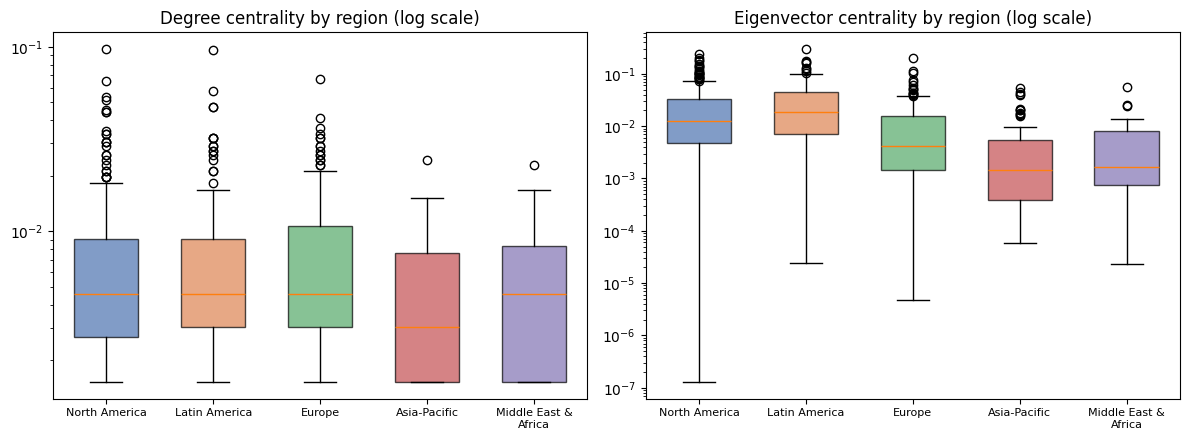

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, measure, title in zip(axes, ["degree_centrality", "eigenvector_centrality"],
                              ["Degree centrality", "Eigenvector centrality"]):
    values_by_region = [organizations_table.loc[organizations_table["region"] == r, measure]
                        for r in REGION_ORDER]
    box = ax.boxplot(values_by_region, patch_artist=True, widths=0.6)
    for patch, region in zip(box["boxes"], REGION_ORDER):
        patch.set_facecolor(REGION_COLORS[region])
        patch.set_alpha(0.7)
    ax.set_yscale("log")
    ax.set_xticks(range(1, len(REGION_ORDER) + 1))
    ax.set_xticklabels([r.replace(" & ", " &\n") for r in REGION_ORDER], fontsize=8)
    ax.set_title(f"{title} by region (log scale)")
plt.tight_layout()
plt.savefig(FIGURE_FOLDER / "centrality_by_region.png", dpi=150)
plt.show()

### Statistical tests

With five groups I use the **Kruskal–Wallis test**, a rank-based version of a one-way ANOVA
that doesn't assume normal data. If it finds a difference, I follow up with **Mann–Whitney
tests** for each pair of regions, using a Bonferroni correction because there are 10 pairs.

In [42]:
for measure in ["degree_centrality", "eigenvector_centrality"]:
    groups = [organizations_table.loc[organizations_table["region"] == r, measure]
              for r in REGION_ORDER]
    statistic, p_value = stats.kruskal(*groups)
    print(f"{measure:24s} Kruskal-Wallis H = {statistic:6.2f}, p = {p_value:.2g}")

degree_centrality        Kruskal-Wallis H =   6.88, p = 0.14
eigenvector_centrality   Kruskal-Wallis H =  93.37, p = 2.5e-19


In [43]:
pair_results = []
region_pairs = [(a, b) for i, a in enumerate(REGION_ORDER) for b in REGION_ORDER[i + 1:]]
for region_a, region_b in region_pairs:
    values_a = organizations_table.loc[organizations_table["region"] == region_a,
                                       "eigenvector_centrality"]
    values_b = organizations_table.loc[organizations_table["region"] == region_b,
                                       "eigenvector_centrality"]
    statistic, p_value = stats.mannwhitneyu(values_a, values_b, alternative="two-sided")
    pair_results.append({
        "region A": region_a,
        "region B": region_b,
        # chance that a random org from A outranks a random org from B
        "P(A > B)": round(statistic / (len(values_a) * len(values_b)), 2),
        "p (Bonferroni)": min(p_value * len(region_pairs), 1.0),
    })
pairwise_eigenvector = pd.DataFrame(pair_results)
pairwise_eigenvector["significant"] = pairwise_eigenvector["p (Bonferroni)"] < 0.05
pairwise_eigenvector["p (Bonferroni)"] = pairwise_eigenvector["p (Bonferroni)"].map(
    lambda p: f"{p:.2g}")
pairwise_eigenvector

,region A,region B,P(A > B),p (Bonferroni),significant
0,North America,Latin America,0.43,0.26,False
1,North America,Europe,0.66,4.3e-08,True
2,North America,Asia-Pacific,0.75,6.7e-08,True
3,North America,Middle East & Africa,0.73,0.003,True
4,Latin America,Europe,0.73,1.4e-11,True
5,Latin America,Asia-Pacific,0.81,3.1e-10,True
6,Latin America,Middle East & Africa,0.79,8.6e-05,True
7,Europe,Asia-Pacific,0.62,0.046,True
8,Europe,Middle East & Africa,0.60,1,False
9,Asia-Pacific,Middle East & Africa,0.47,1,False


### Is it just group size?

A fair question is whether a group looks more central simply because it has more members.
Here the answer is no. Europe has the most organizations in the network, but its
median eigenvector score is about a third of North America's and less than a quarter of
Latin America's. Latin America has half as many organizations as Europe and the
highest median. The table below puts the size of each region next to its
share of the 50 most central organizations by each measure.

In [44]:
top_50_by_degree = ranked_by("degree_centrality").head(50)
top_50_by_eigenvector = ranked_by("eigenvector_centrality").head(50)
size_vs_influence = pd.DataFrame({
    "share of orgs": region_counts / region_counts.sum(),
    "degree top 50": top_50_by_degree["region"].value_counts() / 50,
    "eigenvector top 50": top_50_by_eigenvector["region"].value_counts() / 50,
}).reindex(REGION_ORDER).fillna(0)
(size_vs_influence * 100).round(0).astype(int).astype(str) + "%"

,share of orgs,degree top 50,eigenvector top 50
region,,,
North America,35%,38%,56%
Latin America,17%,28%,34%
Europe,36%,30%,10%
Asia-Pacific,8%,2%,0%
Middle East & Africa,3%,2%,0%


### The most central organization in each region

In [45]:
leaders = []
for region in REGION_ORDER:
    members = organizations_table[organizations_table["region"] == region]
    by_degree = members["degree_centrality"].idxmax()
    by_eigenvector = members["eigenvector_centrality"].idxmax()
    leaders.append({
        "region": region,
        "most partners": f"{by_degree} ({members.loc[by_degree, 'partners']})",
        "highest eigenvector": f"{by_eigenvector} "
                               f"(rank {members.loc[by_eigenvector, 'eigenvector_rank']})",
    })
pd.DataFrame(leaders).set_index("region")

,most partners,highest eigenvector
region,,
North America,Hells Angels Motorcycle Club...,Hells Angels Motorcycle Club...
Latin America,Sinaloa Cartel (63),Sinaloa Cartel (rank 1)
Europe,'Ndrangheta (44),'Ndrangheta (rank 4)
Asia-Pacific,Yamaguchi-gumi (16),Yakuza (rank 66)
Middle East & Africa,Al-Qaeda (15),Hezbollah (rank 61)


### How far does cooperation reach from a hub?

One way to see what centrality means in practice is to start from a hub and see how fast you
reach the rest of the network. Below I count how many organizations are 1, 2, 3
or more steps away from the most central organization in the Americas (the Sinaloa Cartel)
and from the most central Asia-Pacific organization (the Yakuza).

In [46]:
def organizations_by_steps(start):
    steps_away = nx.single_source_shortest_path_length(largest_group, start)
    counts = Counter(steps_away.values())
    return pd.Series({step: counts[step] for step in sorted(counts) if step > 0})


reach = pd.DataFrame({
    "from Sinaloa Cartel": organizations_by_steps("Sinaloa Cartel"),
    "from Yakuza": organizations_by_steps("Yakuza"),
}).fillna(0).astype(int)
reach.index.name = "steps away"
reach["Sinaloa, cumulative %"] = (reach["from Sinaloa Cartel"].cumsum()
                                  / (largest_group.number_of_nodes() - 1) * 100).round(0)
reach["Yakuza, cumulative %"] = (reach["from Yakuza"].cumsum()
                                 / (largest_group.number_of_nodes() - 1) * 100).round(0)
reach

,from Sinaloa Cartel,from Yakuza,"Sinaloa, cumulative %","Yakuza, cumulative %"
steps away,,,,
1,63,7,10.0,1.0
2,234,120,45.0,19.0
3,219,280,78.0,62.0
4,115,190,96.0,91.0
5,24,46,100.0,98.0
6,2,14,100.0,100.0
7,1,1,100.0,100.0


Word travels much faster from the hub. Within two steps the Sinaloa Cartel reaches 45% of the
network, compared with 19% for the Yakuza, and within three steps it's 78% against 62%. Both
can reach every organization in seven steps, so the network is a small world either way, but
the Sinaloa Cartel sits much closer to the middle of it. That's the practical meaning of a
high eigenvector score.

## Active vs. defunct organizations

The second categorical variable splits organizations into active and defunct. This is a
two-group comparison, so it fits the t-test suggested in the assignment. I use **Welch's
t-test**, which doesn't assume equal variances, and back it up with a Mann–Whitney test
because of the skew. The 15 organizations whose status is unknown are left out of this part.

In [47]:
by_status = organizations_table.groupby("status")
status_summary = pd.DataFrame({
    "orgs": by_status.size(),
    "mean partners": by_status["partners"].mean(),
    "median partners": by_status["partners"].median(),
    "mean degree": by_status["degree_centrality"].mean(),
    "mean eigen": by_status["eigenvector_centrality"].mean(),
    "median eigen": by_status["eigenvector_centrality"].median(),
})
display(status_summary.round(4))

active = organizations_table[organizations_table["status"] == "Active"]
defunct = organizations_table[organizations_table["status"] == "Defunct"]
status_tests = []
for measure in ["degree_centrality", "eigenvector_centrality"]:
    welch = stats.ttest_ind(active[measure], defunct[measure], equal_var=False)
    mann_whitney = stats.mannwhitneyu(active[measure], defunct[measure],
                                      alternative="two-sided")
    pooled_sd = np.sqrt((active[measure].var() + defunct[measure].var()) / 2)
    status_tests.append({
        "measure": measure,
        "active mean": round(active[measure].mean(), 4),
        "defunct mean": round(defunct[measure].mean(), 4),
        "Welch t": round(welch.statistic, 2),
        "Welch p": round(welch.pvalue, 3),
        "M-W p": round(mann_whitney.pvalue, 3),
        "Cohen's d": round((active[measure].mean() - defunct[measure].mean()) / pooled_sd, 2),
    })
pd.DataFrame(status_tests).set_index("measure")

,orgs,mean partners,median partners,mean degree,mean eigen,median eigen
status,,,,,,
Active,508,5.6575,3.0,0.0086,0.0210,0.0085
Defunct,136,4.3529,3.0,0.0066,0.0203,0.0106
Unknown,15,2.5333,2.0,0.0039,0.0038,0.0018


,active mean,defunct mean,Welch t,Welch p,M-W p,Cohen's d
measure,,,,,,
degree_centrality,0.0086,0.0066,2.49,0.013,0.050,0.21
eigenvector_centrality,0.0210,0.0203,0.26,0.798,0.125,0.02


## Seeing the network

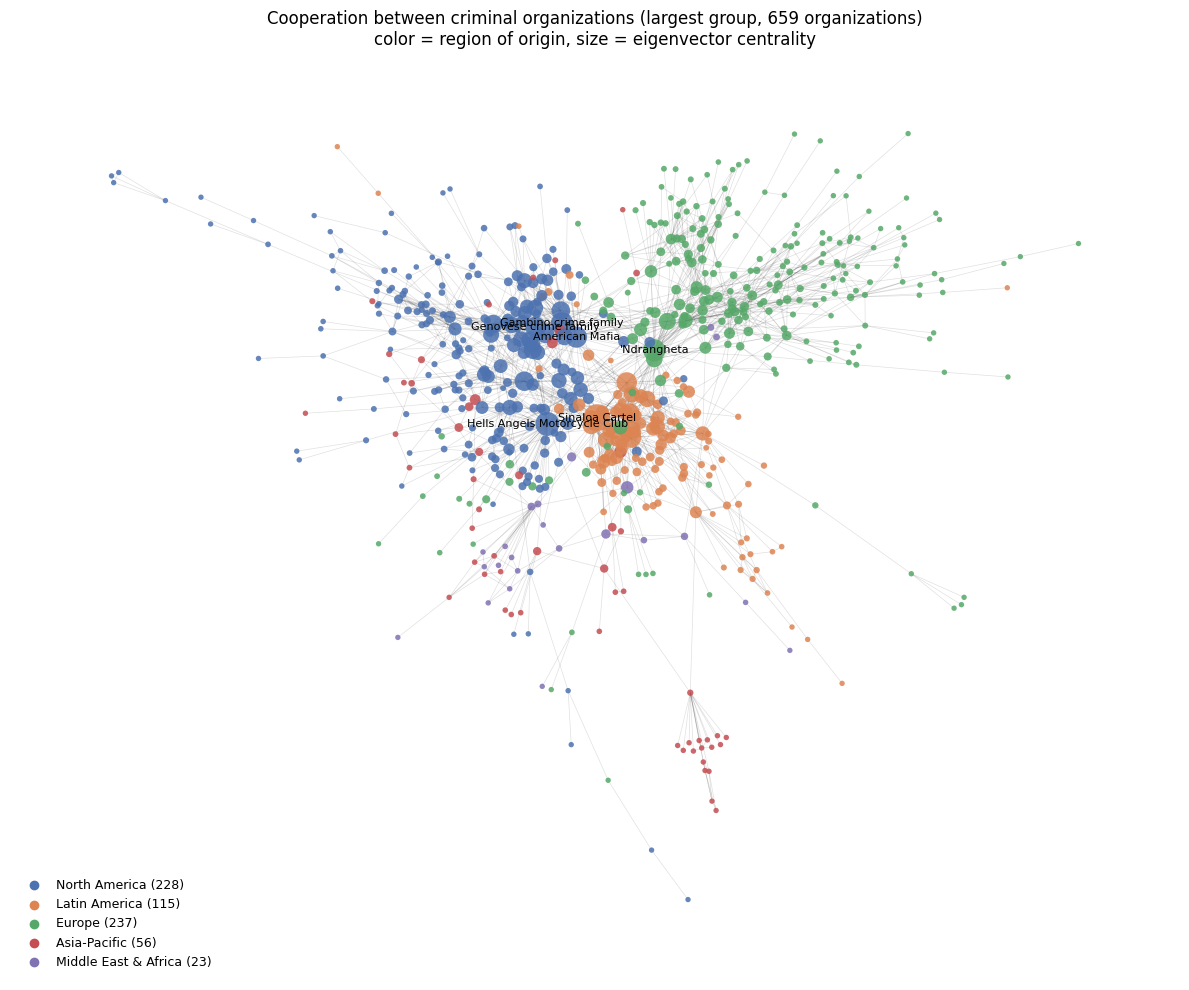

In [48]:
layout = nx.spring_layout(largest_group, seed=42, k=0.12, iterations=100)
eigen_values = organizations_table["eigenvector_centrality"]
node_sizes = [15 + 1200 * eigen_values[name] for name in largest_group]
node_colors = [REGION_COLORS[region_of[name]] for name in largest_group]

fig, ax = plt.subplots(figsize=(12, 10))
nx.draw_networkx_edges(largest_group, layout, alpha=0.12, width=0.5, ax=ax)
nx.draw_networkx_nodes(largest_group, layout, node_size=node_sizes,
                       node_color=node_colors, alpha=0.85, linewidths=0, ax=ax)
labels = {name: name for name in top_by_eigenvector["organization"].head(6)}
nx.draw_networkx_labels(largest_group, layout, labels=labels, font_size=8, ax=ax)
for region in REGION_ORDER:
    ax.scatter([], [], color=REGION_COLORS[region], label=f"{region} ({region_counts[region]})")
ax.legend(loc="lower left", frameon=False, fontsize=9)
ax.set_title("Cooperation between criminal organizations (largest group, 659 organizations)\n"
             "color = region of origin, size = eigenvector centrality")
ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURE_FOLDER / "cooperation_network.png", dpi=150)
plt.show()

## Findings

*(Every number below comes from the outputs above.)*

**Popularity is spread fairly evenly across regions, but influence is not.** The median
organization has 2 or 3 partners in every region, and the Kruskal–Wallis test finds no
significant difference in degree centrality between regions (p = 0.14). Eigenvector
centrality is a different story (p < 0.001), and the Americas dominate. North American and
Latin American organizations score significantly higher than organizations from every
other region, and they don't differ significantly from each other. Europe makes up 36% of
the organizations but only 10% of the eigenvector top 50, while North America and Latin
America together hold 90% of it.

**Why?** Most cooperation stays inside a region (86% of ties), so the network has a few
regional neighborhoods. The biggest and most connected one runs through the United States
and Mexico: the Sinaloa Cartel, the Hells Angels, the American Mafia families and the
Mexican cartels are all tied to each other. Being connected to that core is what drives
eigenvector centrality up. About half of Latin America's ties outside the region (61 of 124)
go to North American organizations. The Italian mafias are just as active by number of
partners, but most of their ties are to other Italian clans (16 of the Camorra's 27 partners
and 21 of the Nuova Famiglia's 22 are Italian), so their influence stays local.

**Who would you target?** If the goal were to disrupt criminal cooperation, the two lists
point to two different kinds of target. The organizations at the top of both lists (Sinaloa,
the Hells Angels, the 'Ndrangheta, the American Mafia) are the obvious hubs. The
eigenvector-only names like the Detroit Partnership or the Tijuana Cartel are the quieter
ones. They aren't the most connected, but they are tied directly to the hubs, which is the
same "guilt by association" idea used in fraud detection.

**Active vs. defunct.** Active organizations have more partners on average, and Welch's
t-test says that difference is significant at the 5% level, but the Mann–Whitney test sits
right on the line and the effect size is small. For eigenvector centrality there's no
difference at all. Organizations CRIMENET lists as defunct, like Los Zetas (rank 9) and the
Cali and Medellín cartels, still sit close to the hubs, because the network keeps every
documented relationship regardless of when it happened.

## Limitations

- **Wikipedia coverage.** An organization only appears if Wikipedia writes about it, and
  English, Italian, Spanish and Portuguese articles cover the Americas and Italy far better
  than Asia or Africa. Some of the regional gap could come from coverage, not from real
  differences in cooperation.
- **Extracted by an LLM.** The relationships were pulled out of text by a language model.
  Every edge has a supporting quote, but some could still be misclassified.
- **Ties across time.** The network combines relationships from different decades, so two
  organizations can be connected even if they were never active at the same time.
- **Mention-only organizations removed.** Dropping them (they have no country) lowers some
  degrees and leaves 63 organizations outside the largest group.
- **Splitting into units.** Italian clans and American Mafia families are separate nodes,
  while some other organizations are single large nodes. That affects how many organizations
  each region has.

## References

- Franco Martins, A. (2026). *CRIMENET: Knowledge Graph of Global Organized Crime.*
  <https://github.com/alvarofrancomartins/CRIMENET> (commit `5b4a897`).
- Tsvetovat, M. and Kouznetsov, A. (2011). *Social Network Analysis for Startups.*
  O'Reilly Media.